
# Employee Data Quality & Human Capital Analytics

## Project Overview

Proyek ini bertujuan untuk menganalisis kualitas data kepegawaian dan mengidentifikasi pola terkait karakteristik pegawai, status kepegawaian, kinerja, serta absensi.

Analisis dilakukan menggunakan Python dan SQL, kemudian hasilnya akan divisualisasikan melalui dashboard interaktif menggunakan Power BI.

**Dataset:** Human Resources Data Set (HRDataset_v14)  
**Source:** [Kaggle - Human Resources Data Set](https://www.kaggle.com/datasets/rhuebner/human-resources-data-set)  
**Tools:** Python, Pandas, SQLite, Power BI  
**Project Type:** Personal Data Analytics Project


### Project Objectives
1. Mengidentifikasi masalah kualitas data seperti missing values, duplikasi, dan inkonsistensi.
2. Membersihkan dan memvalidasi data agar siap dianalisis.
3. Menganalisis komposisi pegawai, status kepegawaian, kinerja, dan absensi.
4. Menyajikan hasil analisis dalam dashboard interaktif.
5. Menghasilkan insight yang dapat mendukung pengelolaan sumber daya manusia.


## 1. Data Loading

Tahap awal dilakukan dengan mengimpor library yang diperlukan dan memuat dataset HRDataset_v14.csv ke dalam DataFrame Pandas.

Dataset asli disimpan dalam variabel `df_raw` agar proses eksplorasi tidak mengubah data sumber.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
import io

# Upload dataset dari penyimpanan lokal.
uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Upload satu file saja: HRDataset_v14.csv")

file_name = next(iter(uploaded))

if not file_name.lower().endswith(".csv"):
    raise ValueError("File yang diupload harus berformat CSV.")

df_raw = pd.read_csv(
    io.BytesIO(uploaded[file_name]),
    encoding="utf-8-sig"
)

print("Dataset berhasil dimuat.")
print(f"Jumlah baris: {df_raw.shape[0]}")
print(f"Jumlah kolom: {df_raw.shape[1]}")

Saving HRDataset_v14.csv to HRDataset_v14 (2).csv
Dataset berhasil dimuat.
Jumlah baris: 311
Jumlah kolom: 36



## 2. Data Understanding

Pada tahap ini, struktur dataset diperiksa untuk mengetahui jumlah observasi, atribut yang tersedia, dan tipe data pada setiap kolom.

Pemeriksaan awal diperlukan untuk menentukan atribut yang relevan dengan analisis Human Capital serta mengidentifikasi kolom yang membutuhkan penyesuaian format.


In [ ]:
# Menampilkan lima baris pertama.
display(df_raw.head())

,Employee_Name,EmpID,MarriedID,MaritalStatusID,GenderID,EmpStatusID,DeptID,PerfScoreID,FromDiversityJobFairID,Salary,Termd,PositionID,Position,State,Zip,DOB,Sex,MaritalDesc,CitizenDesc,HispanicLatino,RaceDesc,DateofHire,DateofTermination,TermReason,EmploymentStatus,Department,ManagerName,ManagerID,RecruitmentSource,PerformanceScore,EngagementSurvey,EmpSatisfaction,SpecialProjectsCount,LastPerformanceReview_Date,DaysLateLast30,Absences
0,"Adinolfi, Wilson K",10026,0,0,1,1,5,4,0,62506,0,19,Production Technician I,MA,1960,07/10/83,M,Single,US Citizen,No,White,7/5/2011,NaN,N/A-StillEmployed,Active,Production,Michael Albert,22.0,LinkedIn,Exceeds,4.60,5,0,1/17/2019,0,1
1,"Ait Sidi, Karthikeyan",10084,1,1,1,5,3,3,0,104437,1,27,Sr. DBA,MA,2148,05/05/75,M,Married,US Citizen,No,White,3/30/2015,6/16/2016,career change,Voluntarily Terminated,IT/IS,Simon Roup,4.0,Indeed,Fully Meets,4.96,3,6,2/24/2016,0,17
2,"Akinkuolie, Sarah",10196,1,1,0,5,5,3,0,64955,1,20,Production Technician II,MA,1810,09/19/88,F,Married,US Citizen,No,White,7/5/2011,9/24/2012,hours,Voluntarily Terminated,Production,Kissy Sullivan,20.0,LinkedIn,Fully Meets,3.02,3,0,5/15/2012,0,3
3,"Alagbe,Trina",10088,1,1,0,1,5,3,0,64991,0,19,Production Technician I,MA,1886,09/27/88,F,Married,US Citizen,No,White,1/7/2008,NaN,N/A-StillEmployed,Active,Production,Elijiah Gray,16.0,Indeed,Fully Meets,4.84,5,0,1/3/2019,0,15
4,"Anderson, Carol",10069,0,2,0,5,5,3,0,50825,1,19,Production Technician I,MA,2169,09/08/89,F,Divorced,US Citizen,No,White,7/11/2011,9/6/2016,return to school,Voluntarily Terminated,Production,Webster Butler,39.0,Google Search,Fully Meets,5.00,4,0,2/1/2016,0,2


In [ ]:
# Memeriksa struktur dan tipe data.
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 36 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Employee_Name               311 non-null    object 
 1   EmpID                       311 non-null    int64  
 2   MarriedID                   311 non-null    int64  
 3   MaritalStatusID             311 non-null    int64  
 4   GenderID                    311 non-null    int64  
 5   EmpStatusID                 311 non-null    int64  
 6   DeptID                      311 non-null    int64  
 7   PerfScoreID                 311 non-null    int64  
 8   FromDiversityJobFairID      311 non-null    int64  
 9   Salary                      311 non-null    int64  
 10  Termd                       311 non-null    int64  
 11  PositionID                  311 non-null    int64  
 12  Position                    311 non-null    object 
 13  State                       311 non

## 3. Missing Value Analysis

Pemeriksaan missing values dilakukan untuk mengetahui kolom yang memiliki data kosong beserta persentasenya terhadap total observasi.

Tidak semua nilai kosong dianggap sebagai kesalahan. Beberapa atribut dapat memiliki nilai kosong yang sesuai dengan kondisi pegawai, sehingga hasil pemeriksaan perlu diinterpretasikan berdasarkan konteks setiap kolom.

In [ ]:
missing_values = df_raw.isnull().sum()

missing_percentage = (
    missing_values / len(df_raw) * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage (%)": missing_percentage
})

missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_summary)

,Missing Values,Percentage (%)
DateofTermination,207,66.56
ManagerID,8,2.57



## 4. Duplicate Data Check

Pemeriksaan duplikasi dilakukan untuk memastikan tidak terdapat pencatatan pegawai yang berulang.

Validasi dilakukan dengan dua pendekatan, yaitu memeriksa duplikasi seluruh baris dan duplikasi berdasarkan `EmpID` sebagai identitas unik pegawai.

Hasil pemeriksaan menjadi dasar untuk menentukan apakah diperlukan penanganan duplikasi pada tahap data cleaning.


In [ ]:
# Duplikasi seluruh baris.
duplicate_rows = df_raw.duplicated().sum()

# Duplikasi berdasarkan ID pegawai.
duplicate_ids = df_raw["EmpID"].duplicated().sum()

unique_employees = df_raw["EmpID"].nunique()

print(f"Total records       : {len(df_raw)}")
print(f"Unique Employee IDs : {unique_employees}")
print(f"Duplicate rows      : {duplicate_rows}")
print(f"Duplicate EmpID     : {duplicate_ids}")


Total records       : 311
Unique Employee IDs : 311
Duplicate rows      : 0
Duplicate EmpID     : 0



## 5. Categorical Data Exploration

Eksplorasi data kategorikal dilakukan untuk memahami distribusi pegawai berdasarkan departemen, status kepegawaian, dan kategori penilaian kinerja.

Pemeriksaan ini juga membantu mengidentifikasi kemungkinan perbedaan penulisan kategori yang dapat memengaruhi hasil agregasi dan visualisasi dashboard.


In [ ]:
categorical_columns = [
    "Department",
    "EmploymentStatus",
    "PerformanceScore"
]

for col in categorical_columns:
    print(f"\nDistribution of {col}")

    summary = df_raw[col].value_counts(
        dropna=False
    ).reset_index()

    summary.columns = [col, "Count"]

    display(summary)


Distribution of Department


,Department,Count
0,Production,209
1,IT/IS,50
2,Sales,31
3,Software Engineering,11
4,Admin Offices,9
5,Executive Office,1



Distribution of EmploymentStatus


,EmploymentStatus,Count
0,Active,207
1,Voluntarily Terminated,88
2,Terminated for Cause,16



Distribution of PerformanceScore


,PerformanceScore,Count
0,Fully Meets,243
1,Exceeds,37
2,Needs Improvement,18
3,PIP,13



## 6. Numerical Data Exploration

Analisis statistik deskriptif dilakukan terhadap atribut numerik untuk memahami rentang nilai, rata-rata, median, dan penyebaran data.

Pemeriksaan ini berguna untuk mengenali karakteristik awal dataset serta mendeteksi nilai yang berpotensi tidak wajar sebelum proses pembersihan dan analisis lanjutan.


In [ ]:
numeric_columns = [
    "Salary",
    "EngagementSurvey",
    "EmpSatisfaction",
    "SpecialProjectsCount",
    "DaysLateLast30",
    "Absences"
]

numeric_summary = df_raw[numeric_columns].describe().T

display(numeric_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
Salary,311.0,69020.68,25156.64,45046.00,55501.50,62810.00,72036.0,250000.0
EngagementSurvey,311.0,4.11,0.79,1.12,3.69,4.28,4.7,5.0
EmpSatisfaction,311.0,3.89,0.91,1.00,3.00,4.00,5.0,5.0
SpecialProjectsCount,311.0,1.22,2.35,0.00,0.00,0.00,0.0,8.0
DaysLateLast30,311.0,0.41,1.29,0.00,0.00,0.00,0.0,6.0
Absences,311.0,10.24,5.85,1.00,5.00,10.00,15.0,20.0



## 7. Initial Data Consistency Check

Selain missing values dan duplikasi, dilakukan pemeriksaan konsistensi antaratribut untuk menemukan kemungkinan ketidaksesuaian dalam data kepegawaian.

Pemeriksaan awal mencakup hubungan antara status terminasi dan tanggal berhenti bekerja, validitas tanggal perekrutan, serta nilai gaji.

Temuan pada tahap ini diperlakukan sebagai indikasi masalah yang perlu ditinjau lebih lanjut, bukan langsung dihapus atau diperbaiki.


In [ ]:
# Konversi sementara untuk pemeriksaan tanggal.
hire_dates = pd.to_datetime(
    df_raw["DateofHire"],
    errors="coerce"
)

termination_dates = pd.to_datetime(
    df_raw["DateofTermination"],
    errors="coerce"
)

# Pemeriksaan aturan dasar kepegawaian.
terminated_without_date = (
    df_raw["Termd"].eq(1) &
    termination_dates.isna()
).sum()

active_with_termination_date = (
    df_raw["Termd"].eq(0) &
    termination_dates.notna()
).sum()

termination_before_hire = (
    termination_dates < hire_dates
).sum()

invalid_hire_dates = hire_dates.isna().sum()

invalid_salary = (
    df_raw["Salary"].isna() |
    df_raw["Salary"].le(0)
).sum()

validation_summary = pd.DataFrame({
    "Validation Check": [
        "Terminated employees without termination date",
        "Non-terminated employees with termination date",
        "Termination date earlier than hire date",
        "Missing or invalid hire dates",
        "Missing or non-positive salary"
    ],
    "Issue Count": [
        terminated_without_date,
        active_with_termination_date,
        termination_before_hire,
        invalid_hire_dates,
        invalid_salary
    ]
})

display(validation_summary)

,Validation Check,Issue Count
0,Terminated employees without termination date,0
1,Non-terminated employees with termination date,0
2,Termination date earlier than hire date,0
3,Missing or invalid hire dates,0
4,Missing or non-positive salary,0



## 8. Initial Data Visualization

Visualisasi awal dibuat untuk memberikan gambaran mengenai distribusi pegawai pada setiap departemen.

Grafik ini bersifat eksploratif dan belum menjadi dashboard final. Hasilnya akan digunakan sebagai referensi dalam menentukan indikator dan visualisasi yang relevan pada tahap pengembangan dashboard Power BI.


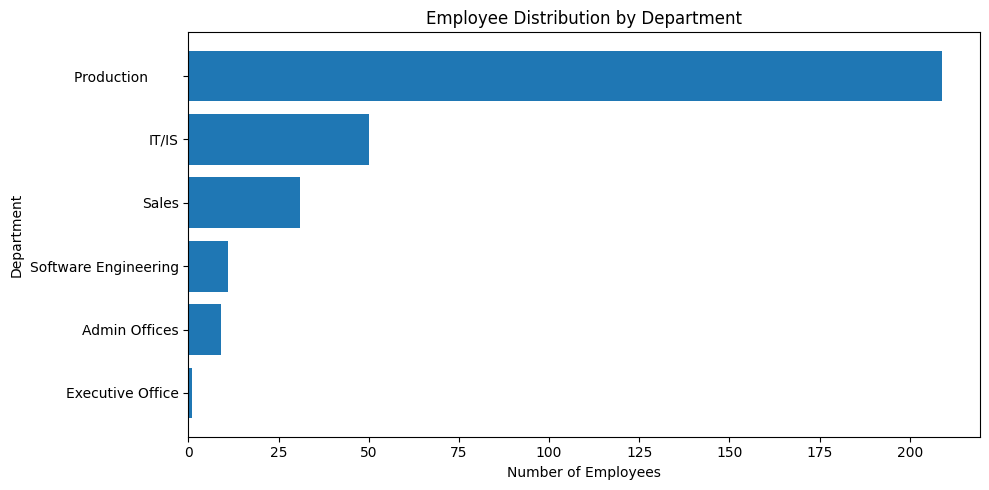

In [ ]:
department_counts = (
    df_raw["Department"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(10, 5))

plt.barh(
    department_counts.index,
    department_counts.values
)

plt.title("Employee Distribution by Department")
plt.xlabel("Number of Employees")
plt.ylabel("Department")

plt.tight_layout()
plt.show()

## 9. Initial Findings

Berdasarkan hasil pemeriksaan awal, dataset memiliki karakteristik sebagai berikut:

- **Dataset size:** Dataset terdiri dari 311 records dan 36 attributes.
- **Unique employees:** Terdapat 311 pegawai unik berdasarkan kolom `EmpID`.
- **Missing values:** Nilai kosong ditemukan pada kolom `DateofTermination` dan `ManagerID`. Kedua kolom tersebut memerlukan pemeriksaan lebih lanjut karena nilai kosong tidak selalu menunjukkan kesalahan data.
- **Duplicate records:** Tidak ditemukan duplikasi seluruh baris maupun duplikasi berdasarkan `EmpID`.
- **Data consistency:** Seluruh pemeriksaan konsistensi awal menunjukkan 0 temuan. Tidak ditemukan ketidaksesuaian antara status terminasi dan tanggal berhenti bekerja, tanggal terminasi yang lebih awal daripada tanggal perekrutan, tanggal perekrutan yang tidak valid, maupun nilai gaji yang kosong atau tidak positif.
- **Workforce distribution:** Departemen Production memiliki jumlah pegawai terbanyak, yaitu 209 pegawai (67,2% dari total dataset), diikuti oleh IT/IS sebanyak 50 pegawai (16,1%) dan Sales sebanyak 31 pegawai (10,0%). Hal ini menunjukkan bahwa mayoritas pegawai dalam dataset berada pada departemen Production.


# Data Cleaning & Validation

## 10. Data Preparation

Proses data cleaning dilakukan untuk memastikan konsistensi format, tipe data, dan kualitas informasi kepegawaian sebelum digunakan dalam analisis lebih lanjut.

Dataset asli dipertahankan sebagai referensi, sedangkan proses pembersihan dilakukan pada salinan DataFrame. Seluruh atribut tetap dipertahankan tanpa menambahkan variabel baru.

Pembersihan dilakukan berdasarkan hasil data understanding, dengan mempertimbangkan konteks setiap atribut agar tidak mengubah informasi yang sudah valid.


In [ ]:

# Membuat salinan dataset untuk proses cleaning.
df_clean = df_raw.copy()

original_shape = df_raw.shape
original_columns = df_raw.columns.tolist()

print("Original dataset:", original_shape)
print("Working dataset :", df_clean.shape)
print("Total columns   :", len(df_clean.columns))


Original dataset: (311, 36)
Working dataset : (311, 36)
Total columns   : 36



## 11. Text Standardization

Standardisasi teks dilakukan dengan menghapus spasi berlebih pada awal dan akhir nilai serta menyamakan representasi data kosong.

Proses ini membantu menghindari perbedaan kategori yang disebabkan oleh masalah penulisan, khususnya pada atribut departemen, jabatan, status kepegawaian, dan nama manajer.

Standardisasi dilakukan tanpa mengubah makna kategori atau informasi asli pegawai.


In [ ]:
# Mengidentifikasi seluruh kolom bertipe teks.
text_columns = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for col in text_columns:
    # Menghapus spasi pada awal dan akhir teks.
    df_clean[col] = df_clean[col].apply(
        lambda value: value.strip()
        if isinstance(value, str) else value
    )

    # Mengubah string kosong menjadi missing value.
    df_clean[col] = df_clean[col].replace(
        r"^\s*$", pd.NA, regex=True
    )

print("Text standardization completed.")
print("Processed text columns:", len(text_columns))


Text standardization completed.
Processed text columns: 18


In [ ]:
# Membandingkan nilai sebelum dan sesudah standardisasi.
text_changes = {}

for col in text_columns:
    before = df_raw[col].astype("string").fillna("<NULL>")
    after = df_clean[col].astype("string").fillna("<NULL>")

    text_changes[col] = int((before != after).sum())

text_changes_summary = pd.DataFrame({
    "Column": list(text_changes.keys()),
    "Modified Values": list(text_changes.values())
})

display(
    text_changes_summary[
        text_changes_summary["Modified Values"] > 0
    ].sort_values("Modified Values", ascending=False)
)

,Column,Modified Values
13,Department,209
4,Sex,135
0,Employee_Name,70
1,Position,1



## 12. Date Format Standardization

Kolom tanggal dikonversi menjadi tipe datetime agar dapat digunakan dalam perhitungan dan analisis berbasis waktu.

Dataset menggunakan format tanggal bulan/hari/tahun, dengan sebagian tahun ditulis menggunakan dua digit. Oleh karena itu, proses konversi juga mencakup pemeriksaan interpretasi tahun pada tanggal lahir.

Koreksi abad pada tanggal lahir hanya dilakukan ketika hasil parsing menunjukkan tanggal lahir setelah tanggal perekrutan dan alternatif pengurangan 100 tahun menghasilkan usia perekrutan yang masuk akal. Setiap perubahan dicatat agar dapat ditelusuri kembali.

In [ ]:

date_columns = [
    "DateofHire",
    "DateofTermination",
    "LastPerformanceReview_Date"
]

date_parse_results = []

for col in date_columns:
    before = df_clean[col].copy()

    df_clean[col] = pd.to_datetime(
        df_clean[col],
        format="mixed",
        dayfirst=False,
        errors="coerce"
    )

    parse_errors = (
        before.notna() & df_clean[col].isna()
    ).sum()

    date_parse_results.append({
        "Column": col,
        "Parsing Errors": int(parse_errors)
    })

display(pd.DataFrame(date_parse_results))


,Column,Parsing Errors
0,DateofHire,0
1,DateofTermination,0
2,LastPerformanceReview_Date,0


In [ ]:
# Menyimpan nilai tanggal lahir sebelum konversi.
dob_original = df_clean["DOB"].copy()

dob_parsed = pd.to_datetime(
    dob_original,
    format="mixed",
    dayfirst=False,
    errors="coerce"
)

# Menguji kemungkinan kesalahan interpretasi abad.
dob_alternative = dob_parsed - pd.DateOffset(years=100)

alternative_hire_age = (
    df_clean["DateofHire"] - dob_alternative
).dt.days / 365.25

century_correction = (
    dob_parsed.gt(df_clean["DateofHire"]) &
    alternative_hire_age.between(16, 80)
)

# Menyimpan riwayat koreksi secara terpisah.
dob_correction_log = pd.DataFrame({
    "EmpID": df_clean.loc[century_correction, "EmpID"],
    "Original DOB": dob_original.loc[century_correction],
    "Parsed DOB": dob_parsed.loc[century_correction],
    "Corrected DOB": dob_alternative.loc[century_correction]
})

# Memperbarui kolom DOB yang sudah ada.
df_clean["DOB"] = dob_parsed.mask(
    century_correction,
    dob_alternative
)

print("DOB century corrections:", century_correction.sum())
print(
    "Unparseable DOB:",
    (dob_original.notna() & dob_parsed.isna()).sum()
)

display(dob_correction_log.head(10))

DOB century corrections: 100
Unparseable DOB: 0


,EmpID,Original DOB,Parsed DOB,Corrected DOB
1,10084,05/05/75,2075-05-05,1975-05-05
8,10114,02/11/70,2070-02-11,1970-02-11
10,10252,01/12/74,2074-01-12,1974-01-12
11,10242,02/21/74,2074-02-21,1974-02-21
16,10023,04/17/66,2066-04-17,1966-04-17
17,10055,10/27/70,2070-10-27,1970-10-27
20,10046,12/22/70,2070-12-22,1970-12-22
21,10226,12/27/58,2058-12-27,1958-12-27
24,10267,01/16/67,2067-01-16,1967-01-16
25,10199,07/30/64,2064-07-30,1964-07-30



## 13. Missing Value Handling

Penanganan missing values dilakukan dengan mempertimbangkan fungsi dan konteks setiap atribut.

Nilai kosong pada `DateofTermination` dipertahankan apabila pegawai masih aktif, karena tanggal terminasi belum berlaku untuk pegawai tersebut.

Sementara itu, missing values pada `ManagerID` tidak diisi secara otomatis untuk menghindari kesalahan penetapan identitas manajer. Record yang belum lengkap akan tetap dipertahankan untuk pemeriksaan lebih lanjut.

Pendekatan ini dipilih agar proses cleaning tidak menghilangkan informasi atau menghasilkan nilai yang tidak didukung oleh data.


In [ ]:
missing_after_cleaning = pd.DataFrame({
    "Missing Values": df_clean.isna().sum(),
    "Percentage (%)": (
        df_clean.isna().mean() * 100
    ).round(2)
})

missing_after_cleaning = missing_after_cleaning[
    missing_after_cleaning["Missing Values"] > 0
].sort_values(
    "Missing Values",
    ascending=False
)

display(missing_after_cleaning)

,Missing Values,Percentage (%)
DateofTermination,207,66.56
ManagerID,8,2.57


In [ ]:
missing_manager = df_clean[
    df_clean["ManagerID"].isna()
][[
    "EmpID",
    "ManagerName",
    "Department",
    "Position",
    "EmploymentStatus"
]]

print("Records with missing ManagerID:", len(missing_manager))

display(missing_manager)

Records with missing ManagerID: 8


,EmpID,ManagerName,Department,Position,EmploymentStatus
19,10277,Webster Butler,Production,Production Technician I,Active
30,10184,Webster Butler,Production,Production Technician II,Active
44,10154,Webster Butler,Production,Production Technician I,Active
88,10136,Webster Butler,Production,Production Technician II,Active
135,10214,Webster Butler,Production,Production Technician II,Active
177,10077,Webster Butler,Production,Production Technician II,Active
232,10011,Webster Butler,Production,Production Technician I,Active
251,10071,Webster Butler,Production,Production Technician I,Active



## 14. Categorical Data Validation

Validasi kategori dilakukan untuk memastikan setiap atribut kategorikal memiliki nilai yang konsisten setelah proses standardisasi.

Pemeriksaan difokuskan pada departemen, status kepegawaian, kategori kinerja, dan jabatan. Nilai kategori asli dipertahankan selama tidak ditemukan inkonsistensi yang dapat diverifikasi.

Tahap ini juga memastikan bahwa perbedaan penulisan tidak menyebabkan penghitungan kategori yang terpisah pada dashboard.

In [ ]:
categorical_columns = [
    "Department",
    "EmploymentStatus",
    "PerformanceScore",
    "Position"
]

for col in categorical_columns:
    print(f"\n{col}")
    print("Unique categories:", df_clean[col].nunique())

    display(
        df_clean[col]
        .value_counts(dropna=False)
        .reset_index(name="Count")
    )


Department
Unique categories: 6


,Department,Count
0,Production,209
1,IT/IS,50
2,Sales,31
3,Software Engineering,11
4,Admin Offices,9
5,Executive Office,1



EmploymentStatus
Unique categories: 3


,EmploymentStatus,Count
0,Active,207
1,Voluntarily Terminated,88
2,Terminated for Cause,16



PerformanceScore
Unique categories: 4


,PerformanceScore,Count
0,Fully Meets,243
1,Exceeds,37
2,Needs Improvement,18
3,PIP,13



Position
Unique categories: 31


,Position,Count
0,Production Technician I,137
1,Production Technician II,57
2,Area Sales Manager,27
3,Production Manager,14
4,Software Engineer,10
5,Data Analyst,8
6,IT Support,8
7,Database Administrator,5
8,Sr. Network Engineer,5
9,Network Engineer,5



## 15. Data Quality Validation

Validasi akhir dilakukan untuk mengevaluasi kualitas dataset setelah proses pembersihan.

Pemeriksaan mencakup keunikan identitas pegawai, konsistensi status dan tanggal terminasi, validitas gaji, kewajaran tanggal lahir, serta kesesuaian tanggal penilaian kinerja.

Temuan dikelompokkan menjadi dua jenis:

- **Error:** Data yang tidak memenuhi aturan validasi dan memerlukan perbaikan.
- **Review:** Data yang perlu diperiksa lebih lanjut sebelum dapat dianggap sebagai kesalahan.

Hasil validasi disimpan dalam laporan terpisah agar tidak mengubah struktur dataset utama.


In [ ]:
# Menyiapkan variabel untuk pemeriksaan aturan bisnis.
termd = pd.to_numeric(df_clean["Termd"], errors="coerce")
salary = pd.to_numeric(df_clean["Salary"], errors="coerce")

hire_age = (
    df_clean["DateofHire"] - df_clean["DOB"]
).dt.days / 365.25

quality_checks = [
    (
        "Missing Employee ID",
        df_clean["EmpID"].isna().sum(),
        "Error"
    ),
    (
        "Duplicate Employee ID",
        df_clean["EmpID"].duplicated().sum(),
        "Error"
    ),
    (
        "Invalid termination flag",
        (~termd.isin([0, 1])).sum(),
        "Error"
    ),
    (
        "Terminated without termination date",
        (termd.eq(1) & df_clean["DateofTermination"].isna()).sum(),
        "Error"
    ),
    (
        "Active with termination date",
        (termd.eq(0) & df_clean["DateofTermination"].notna()).sum(),
        "Error"
    ),
    (
        "Termination before hire date",
        (
            df_clean["DateofTermination"] <
            df_clean["DateofHire"]
        ).sum(),
        "Error"
    ),
    (
        "Missing or invalid hire date",
        df_clean["DateofHire"].isna().sum(),
        "Error"
    ),
    (
        "Missing or non-positive salary",
        (salary.isna() | salary.le(0)).sum(),
        "Error"
    ),
    (
        "Missing ManagerID",
        df_clean["ManagerID"].isna().sum(),
        "Review"
    ),
    (
        "DOB requires further review",
        (df_clean["DOB"].isna() |
         ~hire_age.between(16, 80)).sum(),
        "Review"
    ),
    (
        "Performance review before hire date",
        (
            df_clean["LastPerformanceReview_Date"] <
            df_clean["DateofHire"]
        ).sum(),
        "Review"
    )
]

quality_report = pd.DataFrame(
    quality_checks,
    columns=["Validation Check", "Issue Count", "Category"]
)

display(quality_report)

,Validation Check,Issue Count,Category
0,Missing Employee ID,0,Error
1,Duplicate Employee ID,0,Error
2,Invalid termination flag,0,Error
3,Terminated without termination date,0,Error
4,Active with termination date,0,Error
5,Termination before hire date,0,Error
6,Missing or invalid hire date,0,Error
7,Missing or non-positive salary,0,Error
8,Missing ManagerID,8,Review
9,DOB requires further review,0,Review


In [ ]:
error_count = quality_report.loc[
    quality_report["Category"] == "Error",
    "Issue Count"
].sum()

review_count = quality_report.loc[
    quality_report["Category"] == "Review",
    "Issue Count"
].sum()

print("DATA QUALITY SUMMARY")
print("-" * 35)
print(f"Total employees       : {len(df_clean)}")
print(f"Total attributes      : {df_clean.shape[1]}")
print(f"Validation errors     : {error_count}")
print(f"Review findings       : {review_count}")
print(f"DOB corrections       : {len(dob_correction_log)}")

DATA QUALITY SUMMARY
-----------------------------------
Total employees       : 311
Total attributes      : 36
Validation errors     : 0
Review findings       : 10
DOB corrections       : 100



## 16. Final Dataset Verification

Pemeriksaan akhir dilakukan dengan membandingkan dimensi dataset sebelum dan sesudah proses cleaning.

Seluruh observasi dan atribut asli harus tetap dipertahankan. Perubahan hanya diperbolehkan pada format nilai atau tipe data yang telah melalui proses standardisasi dan validasi.

Hasil pemeriksaan digunakan untuk memastikan dataset siap memasuki tahap analisis eksploratif dan pengembangan dashboard.


In [ ]:
# Memastikan struktur dataset tetap sama.
assert df_clean.shape == original_shape, (
    "Dataset dimensions have changed."
)

assert df_clean.columns.tolist() == original_columns, (
    "Dataset columns have changed."
)

assert not df_clean["EmpID"].duplicated().any(), (
    "Duplicate Employee IDs detected."
)

print("Dataset structure validation passed.")
print(f"Final records    : {len(df_clean)}")
print(f"Final attributes : {df_clean.shape[1]}")

display(df_clean.head())

Dataset structure validation passed.
Final records    : 311
Final attributes : 36


,Employee_Name,EmpID,MarriedID,MaritalStatusID,GenderID,EmpStatusID,DeptID,PerfScoreID,FromDiversityJobFairID,Salary,Termd,PositionID,Position,State,Zip,DOB,Sex,MaritalDesc,CitizenDesc,HispanicLatino,RaceDesc,DateofHire,DateofTermination,TermReason,EmploymentStatus,Department,ManagerName,ManagerID,RecruitmentSource,PerformanceScore,EngagementSurvey,EmpSatisfaction,SpecialProjectsCount,LastPerformanceReview_Date,DaysLateLast30,Absences
0,"Adinolfi, Wilson K",10026,0,0,1,1,5,4,0,62506,0,19,Production Technician I,MA,1960,1983-07-10,M,Single,US Citizen,No,White,2011-07-05,NaT,N/A-StillEmployed,Active,Production,Michael Albert,22.0,LinkedIn,Exceeds,4.60,5,0,2019-01-17,0,1
1,"Ait Sidi, Karthikeyan",10084,1,1,1,5,3,3,0,104437,1,27,Sr. DBA,MA,2148,1975-05-05,M,Married,US Citizen,No,White,2015-03-30,2016-06-16,career change,Voluntarily Terminated,IT/IS,Simon Roup,4.0,Indeed,Fully Meets,4.96,3,6,2016-02-24,0,17
2,"Akinkuolie, Sarah",10196,1,1,0,5,5,3,0,64955,1,20,Production Technician II,MA,1810,1988-09-19,F,Married,US Citizen,No,White,2011-07-05,2012-09-24,hours,Voluntarily Terminated,Production,Kissy Sullivan,20.0,LinkedIn,Fully Meets,3.02,3,0,2012-05-15,0,3
3,"Alagbe,Trina",10088,1,1,0,1,5,3,0,64991,0,19,Production Technician I,MA,1886,1988-09-27,F,Married,US Citizen,No,White,2008-01-07,NaT,N/A-StillEmployed,Active,Production,Elijiah Gray,16.0,Indeed,Fully Meets,4.84,5,0,2019-01-03,0,15
4,"Anderson, Carol",10069,0,2,0,5,5,3,0,50825,1,19,Production Technician I,MA,2169,1989-09-08,F,Divorced,US Citizen,No,White,2011-07-11,2016-09-06,return to school,Voluntarily Terminated,Production,Webster Butler,39.0,Google Search,Fully Meets,5.00,4,0,2016-02-01,0,2



## 17. Exporting Cleaned Data

Dataset hasil cleaning disimpan dalam format CSV untuk digunakan pada tahap analisis berikutnya.

Selain dataset utama, laporan validasi dan log koreksi tanggal lahir juga disimpan sebagai dokumentasi proses pembersihan.

File hasil pengolahan akan digunakan untuk analisis SQL dan pengembangan dashboard Power BI. Dataset asli tetap dipertahankan sebagai referensi.


In [ ]:
from pathlib import Path

output_dir = Path("/content/hr_analytics_output")
output_dir.mkdir(exist_ok=True)

# Menyimpan dataset hasil cleaning.
df_clean.to_csv(
    output_dir / "HRDataset_v14_clean.csv",
    index=False,
    date_format="%Y-%m-%d"
)

# Menyimpan laporan validasi.
quality_report.to_csv(
    output_dir / "data_quality_report.csv",
    index=False
)

# Menyimpan log koreksi tanggal lahir.
dob_correction_log.to_csv(
    output_dir / "dob_correction_log.csv",
    index=False
)

print("Files saved successfully:")

for file in output_dir.iterdir():
    print("-", file.name)

Files saved successfully:
- data_quality_report.csv
- dob_correction_log.csv
- HRDataset_v14_clean.csv


In [ ]:
from google.colab import files
import shutil

# Menggabungkan hasil cleaning menjadi satu ZIP.
archive_path = shutil.make_archive(
    "/content/HR_Analytics_Cleaned_Output",
    "zip",
    output_dir
)

files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## 18. Data Cleaning Summary

Proses data cleaning dilakukan pada 311 record pegawai dengan mempertahankan seluruh 36 atribut asli.

Tahapan pembersihan dan validasi mencakup:

- **Text Standardization:** Membersihkan spasi yang tidak diperlukan dan menyamakan representasi nilai kosong.
- **Date Standardization:** Mengonversi atribut tanggal menjadi tipe datetime serta memeriksa kemungkinan kesalahan interpretasi tahun pada tanggal lahir.
- **Missing Value Handling:** Mempertahankan nilai kosong yang sesuai konteks dan mengidentifikasi data yang membutuhkan verifikasi.
- **Categorical Validation:** Memeriksa konsistensi kategori departemen, status kepegawaian, jabatan, dan penilaian kinerja.
- **Data Quality Validation:** Mengevaluasi keunikan ID pegawai serta konsistensi tanggal, status terminasi, gaji, dan data kinerja.

### Cleaning Results

- **Records retained:** 311 dari 311 records.
- **Attributes retained:** 36 dari 36 attributes.
- **Text values standardized:** [isi berdasarkan output].
- **DOB century corrections:** [isi berdasarkan output].
- **Validation errors:** [isi berdasarkan output].
- **Records requiring review:** [isi berdasarkan pemeriksaan lanjutan].

Seluruh transformasi dilakukan tanpa menambahkan atribut baru atau menghapus record pegawai.


## 19. Reviewing Data Quality Findings

Pemeriksaan lanjutan dilakukan terhadap record yang masih membutuhkan verifikasi, khususnya missing ManagerID dan tanggal penilaian kinerja yang mendahului tanggal perekrutan.

Selain itu, koreksi tahun pada tanggal lahir ditinjau kembali untuk memastikan hasil konversi tidak menghasilkan usia yang tidak wajar.

Record yang membutuhkan verifikasi tetap dipertahankan dalam dataset. Temuan dicatat secara terpisah agar dapat ditindaklanjuti tanpa mengubah informasi asli yang belum terkonfirmasi.


In [ ]:
# Menampilkan pegawai yang belum memiliki ManagerID.
mask_manager = df_clean["ManagerID"].isna()

manager_review = df_clean.loc[
    mask_manager,
    ["EmpID", "ManagerName", "Department", "Position"]
]

display(manager_review)

,EmpID,ManagerName,Department,Position
19,10277,Webster Butler,Production,Production Technician I
30,10184,Webster Butler,Production,Production Technician II
44,10154,Webster Butler,Production,Production Technician I
88,10136,Webster Butler,Production,Production Technician II
135,10214,Webster Butler,Production,Production Technician II
177,10077,Webster Butler,Production,Production Technician II
232,10011,Webster Butler,Production,Production Technician I
251,10071,Webster Butler,Production,Production Technician I


In [ ]:
# Memeriksa penilaian kinerja yang mendahului tanggal masuk kerja.
mask_review = (
    df_clean["LastPerformanceReview_Date"] <
    df_clean["DateofHire"]
)

performance_review = df_clean.loc[
    mask_review,
    [
        "EmpID",
        "DateofHire",
        "LastPerformanceReview_Date",
        "EmploymentStatus",
        "PerformanceScore"
    ]
]

display(performance_review)

,EmpID,DateofHire,LastPerformanceReview_Date,EmploymentStatus,PerformanceScore
104,10142,2014-07-07,2014-01-15,Terminated for Cause,Fully Meets
108,10246,2015-02-16,2015-01-20,Terminated for Cause,Fully Meets


In [ ]:
# Meninjau sampel perubahan tahun tanggal lahir.
display(dob_correction_log.head(15))

# Menghitung usia pegawai pada saat perekrutan.
age_at_hire = (
    df_clean["DateofHire"] - df_clean["DOB"]
).dt.days / 365.25

print("DOB corrections:", len(dob_correction_log))
print("Minimum hiring age:", round(age_at_hire.min(), 1))
print("Maximum hiring age:", round(age_at_hire.max(), 1))

print(
    "Age records requiring review:",
    (~age_at_hire.between(16, 80)).sum())

,EmpID,Original DOB,Parsed DOB,Corrected DOB
1,10084,05/05/75,2075-05-05,1975-05-05
8,10114,02/11/70,2070-02-11,1970-02-11
10,10252,01/12/74,2074-01-12,1974-01-12
11,10242,02/21/74,2074-02-21,1974-02-21
16,10023,04/17/66,2066-04-17,1966-04-17
17,10055,10/27/70,2070-10-27,1970-10-27
20,10046,12/22/70,2070-12-22,1970-12-22
21,10226,12/27/58,2058-12-27,1958-12-27
24,10267,01/16/67,2067-01-16,1967-01-16
25,10199,07/30/64,2064-07-30,1964-07-30


DOB corrections: 100
Minimum hiring age: 19.2
Maximum hiring age: 63.7
Age records requiring review: 0


In [ ]:
# Menyatukan daftar temuan tanpa menambah kolom dataset utama.
review_records = pd.concat([
    df_clean.loc[
        mask_manager, ["EmpID"]
    ].assign(Issue="Missing ManagerID"),

    df_clean.loc[
        mask_review, ["EmpID"]
    ].assign(Issue="Performance review before hire date")
], ignore_index=True)

total_findings = len(review_records)
unique_review_employees = review_records["EmpID"].nunique()

print("Total review findings:", total_findings)
print("Unique employees requiring review:", unique_review_employees)

display(review_records)

Total review findings: 10
Unique employees requiring review: 10


,EmpID,Issue
0,10277,Missing ManagerID
1,10184,Missing ManagerID
2,10154,Missing ManagerID
3,10136,Missing ManagerID
4,10214,Missing ManagerID
5,10077,Missing ManagerID
6,10011,Missing ManagerID
7,10071,Missing ManagerID
8,10142,Performance review before hire date
9,10246,Performance review before hire date


In [ ]:
# Menyimpan temuan untuk dokumentasi dan analisis data quality.
review_records.to_csv(
    output_dir / "records_for_review.csv",
    index=False
)

print("Review records saved successfully.")

Review records saved successfully.



## 18. Data Cleaning Summary

Proses data cleaning dan validasi dilakukan pada 311 record pegawai dengan mempertahankan seluruh 36 atribut asli.

Pembersihan meliputi standardisasi format teks, konversi tipe data tanggal, pemeriksaan missing values, serta validasi konsistensi antaratribut.

### Cleaning Results

- **Records retained:** 311 dari 311 records.
- **Attributes retained:** 36 dari 36 attributes.
- **Duplicate Employee IDs:** 0.
- **Validation errors:** 0 dari delapan aturan validasi utama.
- **Missing ManagerID:** 8 records requiring review.
- **Performance review date inconsistencies:** 2 records requiring review.
- **DOB century corrections:** 100 potential century misinterpretations corrected using a documented rule, subject to verification.
- **Total review findings:** 10 findings.
- **Unique employees requiring review:** 10.

### Key Findings

Hasil validasi menunjukkan bahwa dataset telah memenuhi seluruh aturan konsistensi utama yang diuji. Namun, masih terdapat beberapa record yang membutuhkan verifikasi lebih lanjut, terutama pada informasi manajer dan tanggal penilaian kinerja.

Koreksi tanggal lahir dilakukan untuk menangani kemungkinan kesalahan interpretasi tahun dua digit. Hasil perubahan telah dicatat secara terpisah untuk mendukung proses audit.

Tidak ada pegawai atau atribut yang dihapus selama proses cleaning. Record yang belum dapat diverifikasi tetap dipertahankan agar informasi asli tidak hilang.

### Next Step

Dataset akan digunakan pada tahap Exploratory Data Analysis (EDA) untuk mengidentifikasi pola distribusi pegawai, status kepegawaian, kinerja, kepuasan kerja, keterlibatan pegawai, dan absensi sebagai dasar pengembangan dashboard Power BI.